### RNN with Attention (Possible solution)

Raw shape: (50530, 5)
Unparseable dates: 0
Missing values per column:
 Date/Time                        0
LV ActivePower (kW)              0
Wind Speed (m/s)                 0
Theoretical_Power_Curve (KWh)    0
Wind Direction (°)               0
dtype: int64
Missing after handling: 0

Summary statistics:
        LV ActivePower (kW)  Wind Speed (m/s)  Theoretical_Power_Curve (KWh)
count         50530.000000      50530.000000                   50530.000000
mean           1307.684332          7.557952                    1492.175463
std            1312.459242          4.227166                    1368.018238
min              -2.471405          0.000000                       0.000000
25%              50.677890          4.201395                     161.328167
50%             825.838074          7.104594                    1063.776283
75%            2482.507568         10.300020                    2964.972462
max            3618.732910         25.206011                    3600.000000


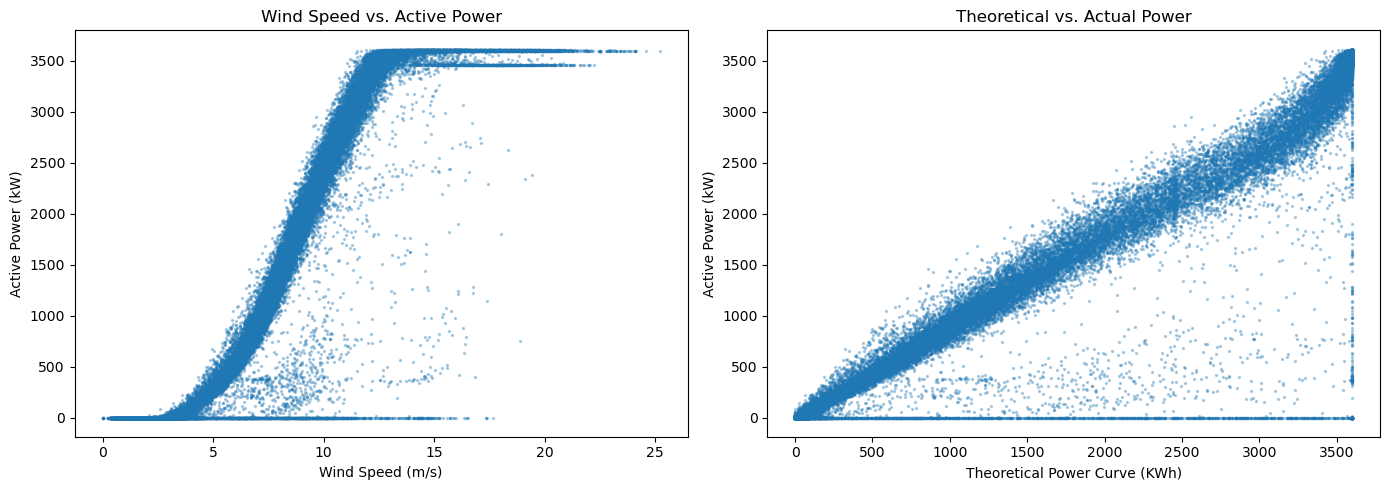

X shape: (50506, 24, 3)
y shape: (50506,)
X_train: (40404, 24, 3) y_train: (40404,)
X_test:  (10102, 24, 3) y_test:  (10102,)


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 24, 3)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 24, 64)              │          17,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 24, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 24, 32)              │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 24, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ attention (AttentionLayer)           │ [(None, 32), (None, 24)]    │           1,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 30,945 (120.88 KB)

 Trainable params: 30,945 (120.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 28s 36ms/step - loss: 0.0200 - val_loss: 0.0151
Epoch 2/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - loss: 0.0099 - val_loss: 0.0080
Epoch 3/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 19s 34ms/step - loss: 0.0077 - val_loss: 0.0080
Epoch 4/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 19s 34ms/step - loss: 0.0068 - val_loss: 0.0064
Epoch 5/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - loss: 0.0063 - val_loss: 0.0056
Epoch 6/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - loss: 0.0061 - val_loss: 0.0054
Epoch 7/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - loss: 0.0059 - val_loss: 0.0055
Epoch 8/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - loss: 0.0059 - val_loss: 0.0054
Epoch 9/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - loss: 0.0057 - val_loss: 0.0054
Epoch 10/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - loss: 0.0055 - val_loss: 0.0053
Epoch 11/30
569/569 ━━━━━━━━━━━━━━━━━━━━ 22s 38ms/step - loss: 0.0054 - val_loss: 0.0054
Epoch 12/30
569/569 ━━━━━━━━━━

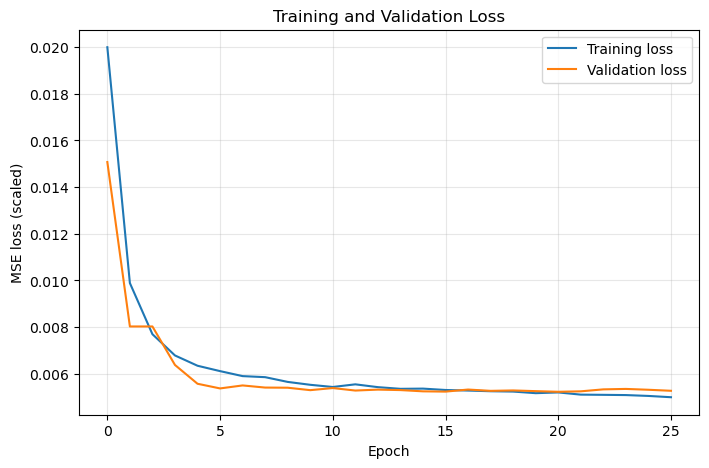

Test loss (scaled MSE): 0.004010
316/316 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step
MSE : 52,584.42 kW^2
RMSE: 229.31 kW
R^2 : 0.9708


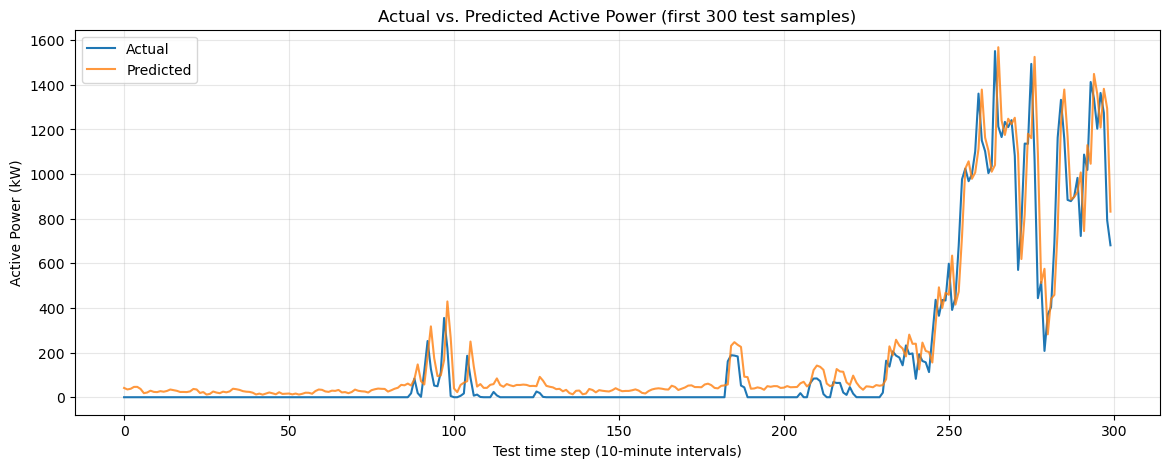

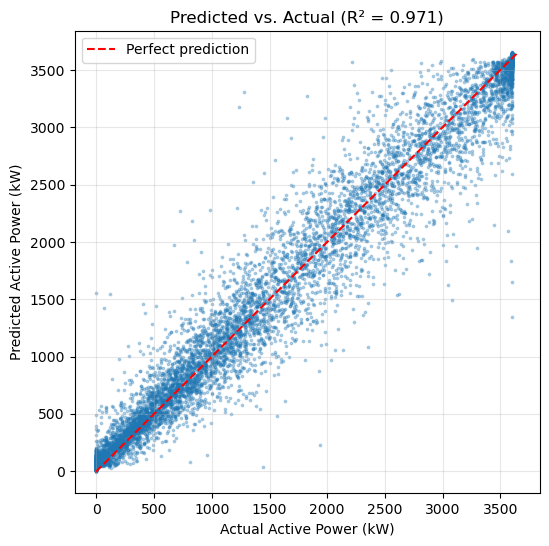

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 899ms/step
316/316 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step


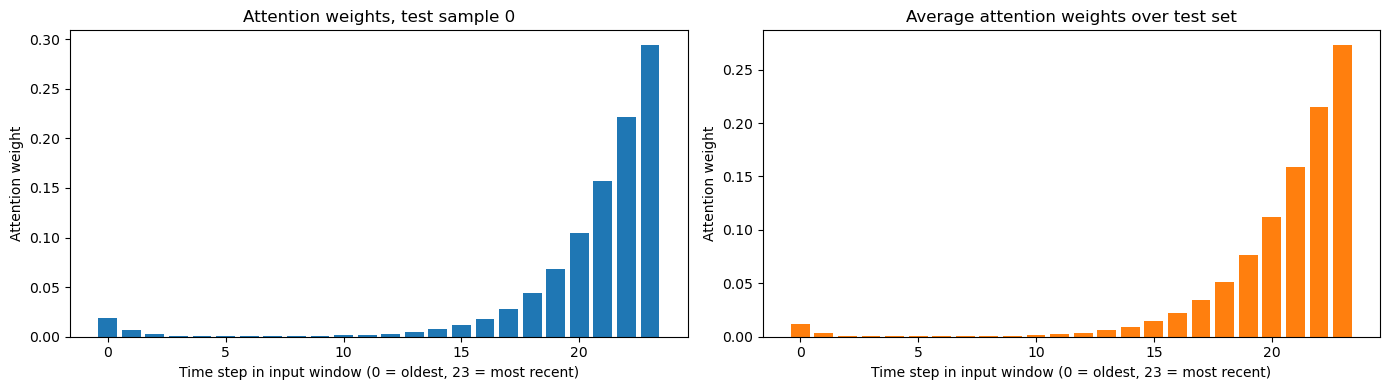

In [2]:
# -*- coding: utf-8 -*-
"""
Wind Turbine Power Prediction with RNNs + Attention

This lab uses an Attention-enhanced Recurrent Neural Network to predict wind turbine power output.
"""

# Step 0: Load libraries & Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, Layer
from tensorflow.keras.callbacks import EarlyStopping
import math

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Step 1: Prepare the Data
DATA_PATH = "T1.csv"          
SEQ_LEN = 24                  # 24 readings x 10 min = 4 hours of history
TRAIN_FRAC = 0.8
FEATURES = ["LV ActivePower (kW)", "Wind Speed (m/s)", "Theoretical_Power_Curve (KWh)"]
TARGET = "LV ActivePower (kW)"

# utf-8-sig strips the hidden byte-order mark at the start of this CSV
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print("Raw shape:", df.shape)

# Convert Date/Time to datetime (format in file: "01 01 2018 00:00")
df["Date/Time"] = pd.to_datetime(df["Date/Time"], format="%d %m %Y %H:%M", errors="coerce")
print("Unparseable dates:", df["Date/Time"].isna().sum())

# Missing values: check, then handle
print("Missing values per column:\n", df.isnull().sum())
df = df.dropna(subset=["Date/Time"]).sort_values("Date/Time").reset_index(drop=True)
df[FEATURES] = df[FEATURES].interpolate(method="linear", limit_direction="both")
print("Missing after handling:", df[FEATURES].isnull().sum().sum())

# Basic EDA
print("\nSummary statistics:\n", df[FEATURES].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(df["Wind Speed (m/s)"], df["LV ActivePower (kW)"], s=2, alpha=0.3)
axes[0].set_xlabel("Wind Speed (m/s)")
axes[0].set_ylabel("Active Power (kW)")
axes[0].set_title("Wind Speed vs. Active Power")
axes[1].scatter(df["Theoretical_Power_Curve (KWh)"], df["LV ActivePower (kW)"], s=2, alpha=0.3)
axes[1].set_xlabel("Theoretical Power Curve (KWh)")
axes[1].set_ylabel("Active Power (kW)")
axes[1].set_title("Theoretical vs. Actual Power")
plt.tight_layout()
plt.show()

# Normalize with MinMaxScaler. Fit on the first 80% of rows (training period)
# only, so no information from the test period leaks into the scaling.
data = df[FEATURES].values
split_row = int(len(data) * TRAIN_FRAC)
scaler = MinMaxScaler()
scaler.fit(data[:split_row])
scaled = scaler.transform(data)
target_idx = FEATURES.index(TARGET)


# Step 2: Create sequences
def create_sequences(arr, seq_len, target_col):
    """X: (samples, seq_len, n_features); y: target value right after each window."""
    X, y = [], []
    for i in range(len(arr) - seq_len):
        X.append(arr[i:i + seq_len])
        y.append(arr[i + seq_len, target_col])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled, SEQ_LEN, target_idx)
print("X shape:", X.shape)   # (N - 24, 24, 3)
print("y shape:", y.shape)   # (N - 24,)
assert X.shape[0] == len(scaled) - SEQ_LEN and X.shape[1:] == (SEQ_LEN, len(FEATURES))


# Step 3: Split the data
# Chronological 80/20 split, no shuffling: shuffling a time series would put
# training windows right next to test windows and overstate performance.
split = int(len(X) * TRAIN_FRAC)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)


# Step 4: Define a Custom Attention Layer
class AttentionLayer(Layer):
    """Additive (Bahdanau-style) attention over the time dimension.
    Input:  (batch, time, units)
    Output: context vector (batch, units), attention weights (batch, time)"""

    def build(self, input_shape):
        units = input_shape[-1]
        self.W = self.add_weight(name="att_W", shape=(units, units),
                                 initializer="glorot_uniform", trainable=True)
        self.b = self.add_weight(name="att_b", shape=(units,),
                                 initializer="zeros", trainable=True)
        self.u = self.add_weight(name="att_u", shape=(units, 1),
                                 initializer="glorot_uniform", trainable=True)
        super().build(input_shape)

    def call(self, x):
        # Alignment scores: (batch, time, 1)
        score = tf.matmul(tf.tanh(tf.matmul(x, self.W) + self.b), self.u)
        # Attention weights sum to 1 across time
        weights = tf.nn.softmax(score, axis=1)
        # Context vector: weighted sum of the hidden states
        context = tf.reduce_sum(weights * x, axis=1)
        return context, tf.squeeze(weights, axis=-1)


# Step 5: Build the RNN Model with Attention
inputs = Input(shape=(SEQ_LEN, len(FEATURES)))
x = LSTM(64, return_sequences=True)(inputs)
x = Dropout(0.2)(x)
x = LSTM(32, return_sequences=True)(x)
x = Dropout(0.2)(x)
context, att_weights = AttentionLayer(name="attention")(x)
outputs = Dense(1)(context)

model = Model(inputs, outputs)
attention_model = Model(inputs, att_weights)   # companion model sharing all weights


# Step 6: Compile and Train the Model
model.compile(optimizer="adam", loss="mse")
model.summary()

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,    # last 10% of training data, kept in time order
    callbacks=[early_stop],
    verbose=1,
)

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (scaled)")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Step 7: Evaluate and Visualize the Results
test_loss = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss (scaled MSE): {test_loss:.6f}")

pred_scaled = model.predict(X_test).flatten()

def inverse_target(v):
    """Inverse-transform the target column back to kW."""
    dummy = np.zeros((len(v), len(FEATURES)))
    dummy[:, target_idx] = v
    return scaler.inverse_transform(dummy)[:, target_idx]

y_pred = inverse_target(pred_scaled)
y_true = inverse_target(y_test)

mse = mean_squared_error(y_true, y_pred)
rmse = math.sqrt(mse)
r2 = r2_score(y_true, y_pred)
print(f"MSE : {mse:,.2f} kW^2")
print(f"RMSE: {rmse:,.2f} kW")
print(f"R^2 : {r2:.4f}")

# Time-series plot (first 300 test points for readability)
n = 300
plt.figure(figsize=(14, 5))
plt.plot(y_true[:n], label="Actual", linewidth=1.5)
plt.plot(y_pred[:n], label="Predicted", linewidth=1.5, alpha=0.8)
plt.xlabel("Test time step (10-minute intervals)")
plt.ylabel("Active Power (kW)")
plt.title("Actual vs. Predicted Active Power (first 300 test samples)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, s=3, alpha=0.3)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Active Power (kW)")
plt.ylabel("Predicted Active Power (kW)")
plt.title(f"Predicted vs. Actual (R² = {r2:.3f})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Attention weights: one sample, and the average over the test set
sample_idx = 0
sample_w = attention_model.predict(X_test[sample_idx:sample_idx + 1])[0]
mean_w = attention_model.predict(X_test).mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(SEQ_LEN), sample_w)
axes[0].set_title(f"Attention weights, test sample {sample_idx}")
axes[0].set_xlabel("Time step in input window (0 = oldest, 23 = most recent)")
axes[0].set_ylabel("Attention weight")
axes[1].bar(range(SEQ_LEN), mean_w, color="tab:orange")
axes[1].set_title("Average attention weights over test set")
axes[1].set_xlabel("Time step in input window (0 = oldest, 23 = most recent)")
axes[1].set_ylabel("Attention weight")
plt.tight_layout()
plt.show()